# 1 — Preparação da precipitação de 10 minutos e agregação horária

Este notebook recebe **XLS/XLSX, CSV ou TXT** com data, hora e precipitação acumulada a cada 10 minutos. Primeiro regulariza a série de 10 minutos e depois soma seis intervalos consecutivos para produzir a precipitação horária utilizada pelos outros notebooks.

Saídas:

- `dados_processados/chuva_10min_padronizada.csv`
- `dados_processados/chuva_horaria_padronizada.csv`
- `dados_processados/chuva_diaria.csv`
- `dados_processados/relatorio_qualidade.json`

O procedimento não preenche chuva ausente. Uma hora só será válida quando possuir os seis registros de 10 minutos; um dia só será completo quando possuir 24 horas válidas, equivalentes a 144 registros de 10 minutos. Antes de executar, coloque o arquivo de entrada na mesma pasta dos notebooks ou informe o caminho completo na célula de configuração.

In [1]:
# Se faltar alguma biblioteca, descomente e execute a linha seguinte uma vez:
# %pip install pandas numpy matplotlib seaborn openpyxl xlrd

from pathlib import Path
import json
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from IPython.display import display
except ImportError:
    display = print

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## Configuração do arquivo

In [2]:
# ALTERE PRINCIPALMENTE ESTA LINHA
ARQUIVO_ENTRADA = Path("chuva_horaria.csv")

# Deixe como None para detectar automaticamente. Se a detecção falhar,
# escreva o nome exato da coluna, por exemplo: "DataHora" ou "Chuva_mm".
COLUNA_DATA_HORA = None
COLUNA_DATA = "Data"
COLUNA_HORA = None
COLUNA_CHUVA = "Chuva"

# Leitura e datas
ABA_EXCEL = 0
SEPARADOR = ";"
ENCODING = "utf-8"
DECIMAL = "."
FORMATO_DATA = "%d-%m-%y %H:%M"
DIA_PRIMEIRO = True

# Estrutura temporal da série original
FREQUENCIA_MINUTOS = 10
# Use "inicio" se 00:00 representa 00:00–00:10.
# Use "fim" se 00:10 representa 00:00–00:10.
MARCA_TEMPORAL = "fim"

# Controle de qualidade
LIMIAR_DIA_CHUVOSO_MM = 0.1
TRATAMENTO_DUPLICADOS = "media"  # "erro", "media", "soma" ou "primeiro"
ARREDONDAR_PARA_GRADE = False     # mantenha False para não deslocar os eventos
PASTA_SAIDA = Path("dados_processados")

assert TRATAMENTO_DUPLICADOS in {"erro", "media", "soma", "primeiro"}
assert MARCA_TEMPORAL in {"inicio", "fim"}
assert 60 % FREQUENCIA_MINUTOS == 0

## Funções de leitura e detecção das colunas

In [3]:
def normalizar_nome(valor):
    texto = unicodedata.normalize("NFKD", str(valor))
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]+", "_", texto.lower()).strip("_")


def ler_arquivo(caminho):
    caminho = Path(caminho)
    if not caminho.exists():
        raise FileNotFoundError(
            f"Arquivo não encontrado: {caminho.resolve()}\n"
            "Altere ARQUIVO_ENTRADA na célula de configuração."
        )
    sufixo = caminho.suffix.lower()
    if sufixo in {".xlsx", ".xls"}:
        return pd.read_excel(caminho, sheet_name=ABA_EXCEL)
    if sufixo in {".csv", ".txt", ".dat"}:
        kwargs = {"encoding": ENCODING, "dtype": str}
        if SEPARADOR is None:
            kwargs.update({"sep": None, "engine": "python"})
        else:
            kwargs["sep"] = SEPARADOR
        try:
            return pd.read_csv(caminho, **kwargs)
        except UnicodeDecodeError:
            kwargs["encoding"] = "latin-1"
            return pd.read_csv(caminho, **kwargs)
    raise ValueError("Formato não aceito. Use XLS, XLSX, CSV, TXT ou DAT.")


def localizar_coluna(df, informada, candidatos, rotulo, obrigatoria=True):
    mapa = {normalizar_nome(c): c for c in df.columns}
    if informada is not None:
        if informada in df.columns:
            return informada
        chave = normalizar_nome(informada)
        if chave in mapa:
            return mapa[chave]
        raise KeyError(f"A coluna informada para {rotulo!r} não existe: {informada}")

    candidatos_norm = [normalizar_nome(c) for c in candidatos]
    for candidato in candidatos_norm:
        if candidato in mapa:
            return mapa[candidato]
    for nome_norm, original in mapa.items():
        if any(c in nome_norm for c in candidatos_norm):
            return original
    if obrigatoria:
        raise KeyError(
            f"Não foi possível detectar a coluna de {rotulo}. "
            f"Colunas encontradas: {list(df.columns)}"
        )
    return None


def converter_numero(serie):
    if pd.api.types.is_numeric_dtype(serie):
        return pd.to_numeric(serie, errors="coerce")
    s = serie.astype("string").str.strip().str.replace(" ", "", regex=False)
    if DECIMAL == ",":
        # Formato brasileiro: 1.234,5 -> 1234.5
        ambos = s.str.contains(",", na=False) & s.str.contains(r"\.", na=False)
        s.loc[ambos] = s.loc[ambos].str.replace(".", "", regex=False)
        s = s.str.replace(",", ".", regex=False)
    return pd.to_numeric(s, errors="coerce")


def converter_data_hora(df):
    col_dt = localizar_coluna(
        df,
        COLUNA_DATA_HORA,
        ["data_hora", "datahora", "datetime", "date_time", "timestamp", "data e hora"],
        "data e hora",
        obrigatoria=False,
    )
    if col_dt is not None:
        bruto = df[col_dt]
    else:
        col_data = localizar_coluna(
            df, COLUNA_DATA, ["data", "date", "dia"], "data", obrigatoria=True
        )
        col_hora = localizar_coluna(
            df, COLUNA_HORA, ["hora", "time", "horario"], "hora", obrigatoria=False
        )
        if col_hora is None:
            bruto = df[col_data]
        else:
            bruto = df[col_data].astype("string") + " " + df[col_hora].astype("string")

    return pd.to_datetime(
        bruto, format=FORMATO_DATA, dayfirst=DIA_PRIMEIRO, errors="coerce"
    )

## Leitura, controle de qualidade e regularização em 10 minutos

In [4]:
bruto = ler_arquivo(ARQUIVO_ENTRADA)
print(f"Arquivo: {ARQUIVO_ENTRADA}")
print(f"Linhas lidas: {len(bruto):,}")
print("Colunas:", list(bruto.columns))
display(bruto.head())

coluna_chuva = localizar_coluna(
    bruto,
    COLUNA_CHUVA,
    ["precipitacao_mm", "precipitacao", "chuva_mm", "chuva", "rain_mm", "rain", "precip"],
    "precipitação",
)

dados = pd.DataFrame({
    "data_hora": converter_data_hora(bruto),
    "precipitacao_mm": converter_numero(bruto[coluna_chuva]),
})

relatorio = {
    "arquivo_entrada": str(ARQUIVO_ENTRADA),
    "linhas_lidas": int(len(bruto)),
    "datas_invalidas": int(dados["data_hora"].isna().sum()),
    "chuvas_nao_numericas_ou_ausentes": int(dados["precipitacao_mm"].isna().sum()),
    "valores_negativos": int((dados["precipitacao_mm"] < 0).sum()),
}

# Precipitações negativas são inválidas e não são convertidas em zero.
dados.loc[dados["precipitacao_mm"] < 0, "precipitacao_mm"] = np.nan
dados = dados.dropna(subset=["data_hora"]).sort_values("data_hora")

# Internamente, cada horário passa a representar o início do intervalo.
# Exemplo com marca no fim: 00:10 é deslocado para 00:00.
if MARCA_TEMPORAL == "fim":
    dados["data_hora"] = dados["data_hora"] - pd.Timedelta(minutes=FREQUENCIA_MINUTOS)

freq = f"{FREQUENCIA_MINUTOS}min"
fora_grade_mask = dados["data_hora"] != dados["data_hora"].dt.floor(freq)
fora_grade = int(fora_grade_mask.sum())
relatorio["registros_fora_da_grade_10min"] = fora_grade
if fora_grade:
    display(dados.loc[fora_grade_mask].head(20))
    if ARREDONDAR_PARA_GRADE:
        warnings.warn(f"Os horários foram arredondados para a grade de {FREQUENCIA_MINUTOS} minutos.")
        dados["data_hora"] = dados["data_hora"].dt.round(freq)
    else:
        raise ValueError(
            f"Existem registros fora da grade de {FREQUENCIA_MINUTOS} minutos. "
            "Verifique os horários ou, se for justificável, defina ARREDONDAR_PARA_GRADE=True."
        )

n_duplicados = int(dados.duplicated("data_hora", keep=False).sum())
relatorio["linhas_em_horarios_duplicados"] = n_duplicados
if n_duplicados:
    if TRATAMENTO_DUPLICADOS == "erro":
        duplicados = dados[dados.duplicated("data_hora", keep=False)].head(20)
        display(duplicados)
        raise ValueError("Há horários duplicados. Corrija-os ou altere TRATAMENTO_DUPLICADOS.")
    if TRATAMENTO_DUPLICADOS == "media":
        dados = dados.groupby("data_hora", as_index=False)["precipitacao_mm"].mean()
    elif TRATAMENTO_DUPLICADOS == "soma":
        dados = dados.groupby("data_hora", as_index=False)["precipitacao_mm"].sum(min_count=1)
    else:
        dados = dados.drop_duplicates("data_hora", keep="first")

inicio = dados["data_hora"].min().floor(freq)
fim = dados["data_hora"].max().floor(freq)
grade = pd.date_range(inicio, fim, freq=freq)
dez_min = dados.set_index("data_hora").reindex(grade)
dez_min.index.name = "data_hora"
dez_min["registro_valido"] = dez_min["precipitacao_mm"].notna()

# Agregação determinística: seis acumulados de 10 min formam uma hora.
intervalos_por_hora = 60 // FREQUENCIA_MINUTOS
grupos_hora = dez_min["precipitacao_mm"].resample("h")
horario = pd.DataFrame({
    "n_intervalos_validos": grupos_hora.count().astype(int),
    "precipitacao_mm": grupos_hora.sum(min_count=intervalos_por_hora),
})
horario.index.name = "data_hora"
horario["registro_valido"] = horario["n_intervalos_validos"].eq(intervalos_por_hora)
horario.loc[~horario["registro_valido"], "precipitacao_mm"] = np.nan

relatorio["inicio"] = str(inicio)
relatorio["fim"] = str(fim)
relatorio["frequencia_original_minutos"] = int(FREQUENCIA_MINUTOS)
relatorio["marca_temporal_original"] = MARCA_TEMPORAL
relatorio["intervalos_10min_na_grade"] = int(len(dez_min))
relatorio["intervalos_10min_validos"] = int(dez_min["registro_valido"].sum())
relatorio["intervalos_10min_ausentes"] = int((~dez_min["registro_valido"]).sum())
relatorio["horas_na_grade"] = int(len(horario))
relatorio["horas_validas"] = int(horario["registro_valido"].sum())
relatorio["horas_ausentes"] = int((~horario["registro_valido"]).sum())

print(json.dumps(relatorio, indent=2, ensure_ascii=False))
print("\nPrimeiros registros de 10 minutos:")
display(dez_min.head(12))
print("\nPrimeiros acumulados horários:")
display(horario.head(12))

Arquivo: chuva_horaria.csv
Linhas lidas: 567,379
Colunas: ['Data', 'Chuva']


,Data,Chuva
0,17-12-14 20:10,0.2
1,17-12-14 20:20,0
2,17-12-14 20:30,0
3,17-12-14 20:40,0
4,17-12-14 20:50,0


{
  "arquivo_entrada": "chuva_horaria.csv",
  "linhas_lidas": 567379,
  "datas_invalidas": 0,
  "chuvas_nao_numericas_ou_ausentes": 0,
  "valores_negativos": 0,
  "registros_fora_da_grade_10min": 0,
  "linhas_em_horarios_duplicados": 0,
  "inicio": "2014-12-17 20:00:00",
  "fim": "2025-09-30 23:00:00",
  "frequencia_original_minutos": 10,
  "marca_temporal_original": "fim",
  "intervalos_10min_na_grade": 567379,
  "intervalos_10min_validos": 567379,
  "intervalos_10min_ausentes": 0,
  "horas_na_grade": 94564,
  "horas_validas": 94563,
  "horas_ausentes": 1
}

Primeiros registros de 10 minutos:


,precipitacao_mm,registro_valido
data_hora,,
2014-12-17 20:00:00,0.2,True
2014-12-17 20:10:00,0.0,True
2014-12-17 20:20:00,0.0,True
2014-12-17 20:30:00,0.0,True
2014-12-17 20:40:00,0.0,True
2014-12-17 20:50:00,0.0,True
2014-12-17 21:00:00,0.0,True
2014-12-17 21:10:00,0.0,True
2014-12-17 21:20:00,0.0,True



Primeiros acumulados horários:


,n_intervalos_validos,precipitacao_mm,registro_valido
data_hora,,,
2014-12-17 20:00:00,6,0.2,True
2014-12-17 21:00:00,6,0.0,True
2014-12-17 22:00:00,6,1.6,True
2014-12-17 23:00:00,6,1.4,True
2014-12-18 00:00:00,6,0.0,True
2014-12-18 01:00:00,6,0.0,True
2014-12-18 02:00:00,6,0.0,True
2014-12-18 03:00:00,6,0.0,True
2014-12-18 04:00:00,6,0.0,True


## Agregação diária sem preenchimento de falhas

In [5]:
grupos = horario.groupby(horario.index.normalize())
diaria = pd.DataFrame({
    "n_horas_validas": grupos["registro_valido"].sum().astype(int),
    "precipitacao_diaria_mm": grupos["precipitacao_mm"].sum(min_count=24),
})
diaria.index.name = "data"
diaria["dia_completo"] = diaria["n_horas_validas"].eq(24)
diaria["dia_chuvoso"] = (
    diaria["dia_completo"]
    & diaria["precipitacao_diaria_mm"].ge(LIMIAR_DIA_CHUVOSO_MM)
)

relatorio["dias_na_serie"] = int(len(diaria))
relatorio["dias_completos"] = int(diaria["dia_completo"].sum())
relatorio["dias_incompletos"] = int((~diaria["dia_completo"]).sum())
relatorio["dias_chuvosos_completos"] = int(diaria["dia_chuvoso"].sum())

resumo_mensal = diaria.assign(mes=diaria.index.to_period("M")).groupby("mes").agg(
    dias=("dia_completo", "size"),
    dias_completos=("dia_completo", "sum"),
    precipitacao_mm=("precipitacao_diaria_mm", "sum"),
)
resumo_mensal["completude_pct"] = 100 * resumo_mensal["dias_completos"] / resumo_mensal["dias"]

display(diaria.head())
display(resumo_mensal.tail(24))

,n_horas_validas,precipitacao_diaria_mm,dia_completo,dia_chuvoso
data,,,,
2014-12-17,4,<NA>,False,False
2014-12-18,24,0.2,True,True
2014-12-19,24,0.0,True,False
2014-12-20,24,35.6,True,True
2014-12-21,24,35.0,True,True


,dias,dias_completos,precipitacao_mm,completude_pct
mes,,,,
2023-10,31,31,191.2,100.000000
2023-11,30,30,322.6,100.000000
2023-12,31,31,186.6,100.000000
2024-01,31,31,160.4,100.000000
2024-02,29,29,117.0,100.000000
2024-03,31,31,102.4,100.000000
2024-04,30,30,514.2,100.000000
2024-05,31,31,566.8,100.000000
2024-06,30,30,235.4,100.000000


## Gráficos de diagnóstico

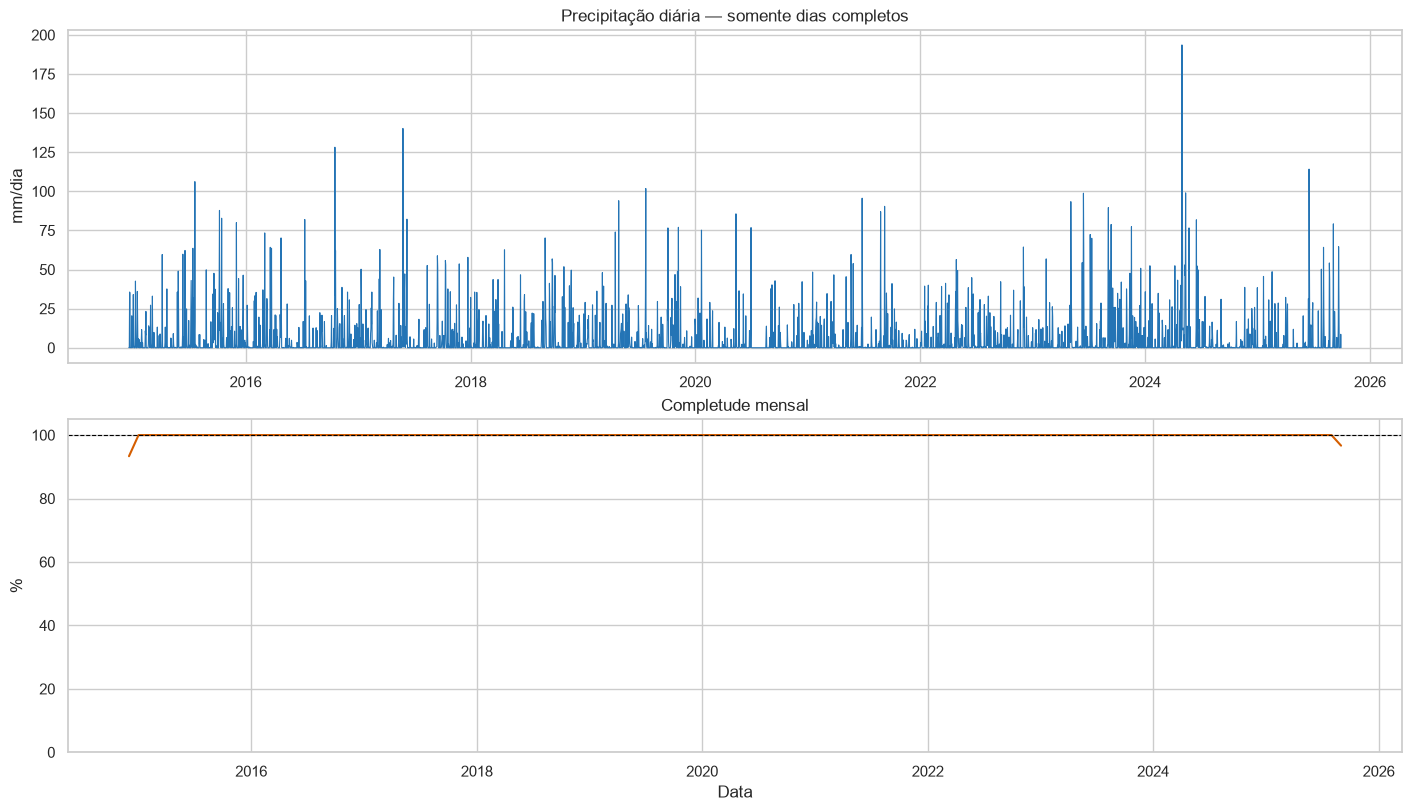

Dias incompletos: 2


,n_horas_validas
data,
2014-12-17,4
2025-09-30,23


In [6]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True)
axes[0].plot(diaria.index, diaria["precipitacao_diaria_mm"], lw=0.8, color="#2474B5")
axes[0].set(title="Precipitação diária — somente dias completos", ylabel="mm/dia")

x_mes = resumo_mensal.index.to_timestamp()
axes[1].plot(x_mes, resumo_mensal["completude_pct"], color="#D55E00")
axes[1].axhline(100, color="black", lw=0.8, ls="--")
axes[1].set(title="Completude mensal", ylabel="%", xlabel="Data", ylim=(0, 105))
plt.show()

incompletos = diaria.loc[~diaria["dia_completo"], ["n_horas_validas"]]
print(f"Dias incompletos: {len(incompletos):,}")
display(incompletos.head(20))

## Exportação

In [7]:
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

caminho_10min = PASTA_SAIDA / "chuva_10min_padronizada.csv"
caminho_horario = PASTA_SAIDA / "chuva_horaria_padronizada.csv"
caminho_diario = PASTA_SAIDA / "chuva_diaria.csv"
caminho_relatorio = PASTA_SAIDA / "relatorio_qualidade.json"

dez_min.reset_index().to_csv(caminho_10min, index=False, date_format="%Y-%m-%d %H:%M:%S")
horario.reset_index().to_csv(caminho_horario, index=False, date_format="%Y-%m-%d %H:%M:%S")
diaria.reset_index().to_csv(caminho_diario, index=False, date_format="%Y-%m-%d")
with open(caminho_relatorio, "w", encoding="utf-8") as f:
    json.dump(relatorio, f, indent=2, ensure_ascii=False)

print("Arquivos criados:")
print(" -", caminho_10min.resolve())
print(" -", caminho_horario.resolve())
print(" -", caminho_diario.resolve())
print(" -", caminho_relatorio.resolve())
print("\nAgora execute o notebook 02_treinamento_gru.ipynb.")

Arquivos criados:
 - B:\Codigos\DesgracaoChuvas\dados_processados\chuva_10min_padronizada.csv
 - B:\Codigos\DesgracaoChuvas\dados_processados\chuva_horaria_padronizada.csv
 - B:\Codigos\DesgracaoChuvas\dados_processados\chuva_diaria.csv
 - B:\Codigos\DesgracaoChuvas\dados_processados\relatorio_qualidade.json

Agora execute o notebook 02_treinamento_gru.ipynb.
